# Lab 3: Clustering Analysis Using K-Means and K-Medoids Algorithms

**Name:** Federico Poi  
**Course:** MSCS-634 Advanced Big Data and Data Mining  
**Assignment:** Lab 3  
**Dataset:** Wine Dataset from scikit-learn

## Step 1: Load and Prepare the Dataset
The Wine dataset holds 178 wine samples, each described by 13 chemical measurements and tagged with the cultivar it came from. Those labels are only used at the end to score the clusters. The clustering itself never sees them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.metrics import confusion_matrix

# Load the dataset. X holds the 13 chemical features, y holds the true cultivar
# labels, which stay unused until the ARI evaluation in Steps 2 and 3.
wine = load_wine()
X_raw = wine.data
y_true = wine.target

df = pd.DataFrame(X_raw, columns=wine.feature_names)
df['cultivar'] = y_true
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 1.1 Feature Details

In [2]:
print('Shape:', df.shape)
print('Features:', len(wine.feature_names))
print('Missing values:', int(df.isnull().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))

# Pull out the spread of each feature. The std and max columns are what justify
# standardizing in section 1.4.
summary = df[wine.feature_names].describe().T[['mean', 'std', 'min', 'max']]
summary

Shape: (178, 14)
Features: 13
Missing values: 0
Duplicate rows: 0


,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


The table shows the problem this dataset has. `proline` has a standard deviation of about 315 and reaches 1,680, while `nonflavanoid_phenols` varies by about 0.12 and never passes 0.66. Clustering measures distance, so without rescaling, `proline` alone would decide which points land together and the other 12 features would be close to decoration.

### 1.2 Class Distribution

Samples per cultivar:
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

Proportions:
class_0    0.331
class_1    0.399
class_2    0.270
Name: count, dtype: float64


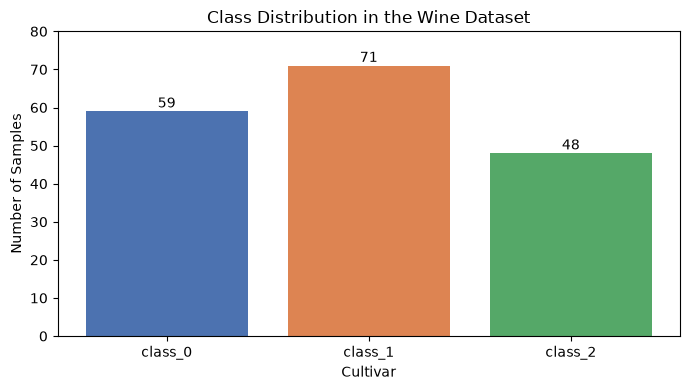

In [3]:
# Count samples per cultivar. Roughly balanced classes matter for ARI, which
# would be harder to read if one class dominated.
class_counts = df['cultivar'].value_counts().sort_index()
class_counts.index = wine.target_names
print('Samples per cultivar:')
print(class_counts)
print('\nProportions:')
print((class_counts / len(df)).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=['#4C72B0', '#DD8452', '#55A868'])
# Label each bar with its count so the exact numbers are readable from the plot.
for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 1, str(count), ha='center')
ax.set_title('Class Distribution in the Wine Dataset')
ax.set_xlabel('Cultivar'); ax.set_ylabel('Number of Samples')
ax.set_ylim(0, 80)
plt.tight_layout(); plt.show()

The three cultivars hold 59, 71, and 48 samples, so the largest class is only about 1.5 times the smallest. That balance is convenient: a clustering algorithm that splits the data into three roughly even groups is not automatically rewarded, and ARI stays interpretable.

### 1.3 Feature Scale Comparison
Before standardizing, it helps to see the scale gap directly rather than reading it off a table.

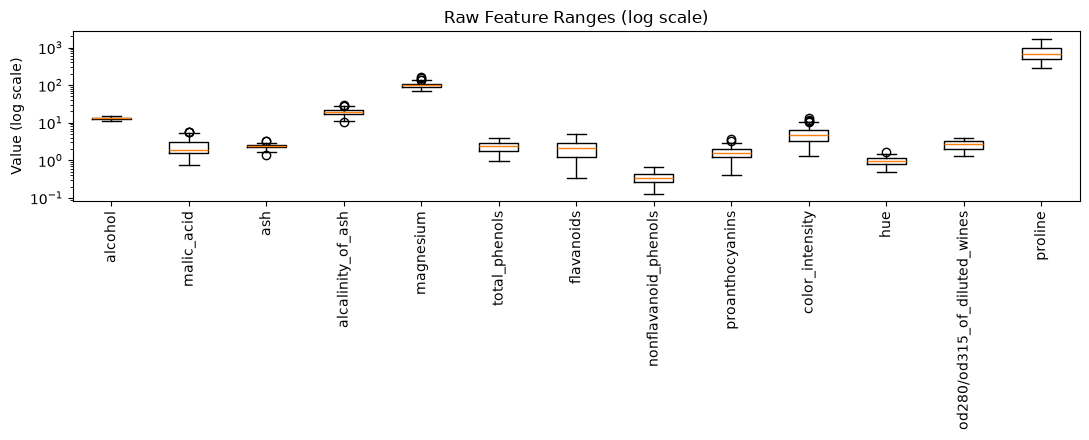

In [4]:
# Boxplot on raw features, log scale on the y axis. A linear axis would squash
# all 12 other features into a flat line next to proline.
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([X_raw[:, i] for i in range(X_raw.shape[1])],
           tick_labels=wine.feature_names, vert=True)
ax.set_yscale('log')
ax.set_title('Raw Feature Ranges (log scale)')
ax.set_ylabel('Value (log scale)')
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

On a log axis the gap spans roughly four orders of magnitude, from `nonflavanoid_phenols` near 0.1 up to `proline` near 1,700. Any distance computed on these raw numbers is effectively a distance in `proline` and `magnesium` only.

### 1.4 Standardization with Z-Score Normalization
Z-score normalization rewrites each feature as `(value - mean) / std`, so every feature ends up centered at 0 with unit variance and all 13 contribute to the distance calculation on equal footing.

In [5]:
# Standardize so every feature has mean 0 and standard deviation 1.
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

scaled = pd.DataFrame(X, columns=wine.feature_names)
check = pd.DataFrame({'mean_before': X_raw.mean(axis=0), 'std_before': X_raw.std(axis=0),
                      'mean_after': scaled.mean().values, 'std_after': scaled.std(ddof=0).values},
                     index=wine.feature_names)
print('Before and after standardization:')
check.round(3)

Before and after standardization:


,mean_before,std_before,mean_after,std_after
alcohol,13.001,0.810,0.0,1.0
malic_acid,2.336,1.114,0.0,1.0
ash,2.367,0.274,-0.0,1.0
alcalinity_of_ash,19.495,3.330,-0.0,1.0
magnesium,99.742,14.242,-0.0,1.0
total_phenols,2.295,0.624,-0.0,1.0
flavanoids,2.029,0.996,0.0,1.0
nonflavanoid_phenols,0.362,0.124,-0.0,1.0
proanthocyanins,1.591,0.571,-0.0,1.0
color_intensity,5.058,2.312,-0.0,1.0


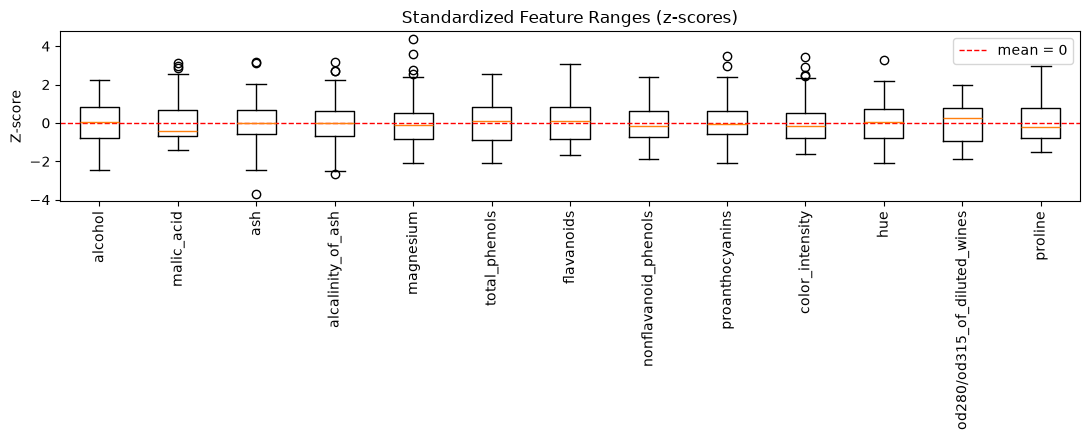

In [6]:
# Same boxplot as before, now on the standardized data, to confirm the fix.
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([X[:, i] for i in range(X.shape[1])], tick_labels=wine.feature_names, vert=True)
ax.axhline(0, color='red', linestyle='--', linewidth=1, label='mean = 0')
ax.set_title('Standardized Feature Ranges (z-scores)')
ax.set_ylabel('Z-score'); ax.legend()
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

Every box now sits on the same vertical scale, centered on zero and mostly within about two standard deviations. The outliers that remain, visible in `magnesium` and `proanthocyanins`, are real high values in the data rather than scaling artifacts, and they matter later: K-Means is pulled by them while K-Medoids is not.

### 1.5 Projecting to Two Dimensions for Plotting
The data lives in 13 dimensions, which cannot be plotted directly. PCA compresses it to two components for the scatter plots in Step 4. Clustering still runs on all 13 standardized features; PCA is only used for display.

In [7]:
# PCA for visualization only. Both clustering algorithms still see all 13 features.
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

explained = pca.explained_variance_ratio_
print(f'PC1 explains {explained[0]:.1%} of the variance')
print(f'PC2 explains {explained[1]:.1%} of the variance')
print(f'Together: {explained.sum():.1%}')

PC1 explains 36.2% of the variance
PC2 explains 19.2% of the variance
Together: 55.4%


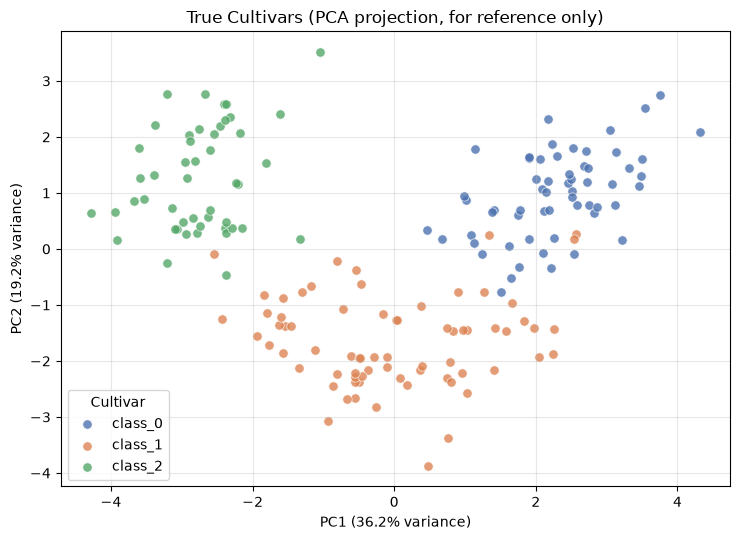

In [8]:
# Scatter of the true cultivars, as a reference for the cluster plots in Step 4.
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for class_id, name, color in zip(range(3), wine.target_names, ['#4C72B0', '#DD8452', '#55A868']):
    mask = y_true == class_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=name, s=45, alpha=0.8,
               edgecolors='white', linewidths=0.5)
ax.set_title('True Cultivars (PCA projection, for reference only)')
ax.set_xlabel(f'PC1 ({explained[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({explained[1]:.1%} variance)')
ax.legend(title='Cultivar'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The two components carry about 55% of the variance, which is enough to see the structure. The three cultivars form visibly separate groups, though `class_1` in the middle brushes against both of its neighbors. That overlap region is where both algorithms make their mistakes.

## Step 2: Implement K-Means Clustering
K-Means picks `k` centroids, assigns every point to its nearest one, then moves each centroid to the mean of the points assigned to it, repeating until nothing moves. A centroid is an average position, so it does not have to match any real sample. `k = 3` here because the dataset has three cultivars.

In [9]:
# n_init=10 runs the algorithm 10 times from different starts and keeps the best
# result by inertia, which guards against a bad random initialization.
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

print('Cluster sizes:', np.bincount(kmeans_labels))
print('Iterations until convergence:', kmeans.n_iter_)
print(f'Inertia (within-cluster sum of squares): {kmeans.inertia_:.2f}')

Cluster sizes: [65 51 62]
Iterations until convergence: 7
Inertia (within-cluster sum of squares): 1277.93


### 2.1 Performance Metrics
Silhouette Score measures how tight and separated the clusters are, using only the data, and runs from -1 to 1. Adjusted Rand Index compares the clusters against the true cultivars, where 0 means no better than random and 1 means a perfect match.

In [10]:
# Silhouette uses only the features. ARI brings in the true labels.
kmeans_silhouette = silhouette_score(X, kmeans_labels)
kmeans_ari = adjusted_rand_score(y_true, kmeans_labels)

print('K-Means (k = 3)')
print(f'  Silhouette Score      : {kmeans_silhouette:.4f}')
print(f'  Adjusted Rand Index   : {kmeans_ari:.4f}')

K-Means (k = 3)
  Silhouette Score      : 0.2849
  Adjusted Rand Index   : 0.8975


In [11]:
# Cross-tabulate clusters against true cultivars. Cluster numbers are arbitrary,
# so read the table by which row lines up with which column.
kmeans_crosstab = pd.DataFrame(
    confusion_matrix(y_true, kmeans_labels),
    index=[f'true_{n}' for n in wine.target_names],
    columns=[f'cluster_{i}' for i in range(3)])
print('K-Means clusters vs true cultivars:')
kmeans_crosstab

K-Means clusters vs true cultivars:


,cluster_0,cluster_1,cluster_2
true_class_0,0,0,59
true_class_1,65,3,3
true_class_2,0,48,0


The clusters come out at 65, 51, and 62 samples against true counts of 59, 71, and 48, so the sizes are close but not exact. The table shows a nearly clean recovery, with the errors being a handful of samples shifting out of the middle class, which lines up with the overlap seen in the PCA plot.

## Step 3: Implement K-Medoids Clustering
K-Medoids works the same way but each cluster center has to be an actual sample from the dataset, called a medoid, chosen to minimize the total distance to the other members of its cluster. Because a medoid is a real point rather than an average, a single extreme value cannot drag it away the way it can drag a centroid.

`scikit-learn` does not ship K-Medoids. The usual add-on, `scikit-learn-extra`, has no wheels for current Python versions and its source build fails while compiling a C++ extension, so it is not a dependency worth relying on. The PAM (Partitioning Around Medoids) algorithm is implemented directly below instead, which keeps the notebook runnable with nothing beyond the standard scientific stack. Section 3.2 then checks the result against the maintained `kmedoids` library to confirm the implementation is correct.

In [12]:
def k_medoids(X, k, random_state=42, max_iter=300):
    """Partitioning Around Medoids (PAM) clustering.

    Returns (medoid_indices, labels, n_iter). Medoids are indices into X, so each
    cluster center is a real sample rather than an average position.
    """
    D = cdist(X, X)                      # full pairwise Euclidean distance matrix
    n = len(X)
    rng = np.random.RandomState(random_state)

    # Initialize with k-means++ style seeding: spread the first medoids out so a
    # bad random draw cannot put two of them inside the same natural cluster.
    medoids = [rng.randint(n)]
    for _ in range(1, k):
        d_sq = D[medoids].min(axis=0) ** 2
        medoids.append(rng.choice(n, p=d_sq / d_sq.sum()))
    medoids = np.array(medoids)

    for iteration in range(max_iter):
        labels = D[:, medoids].argmin(axis=1)     # assign each point to nearest medoid
        updated = medoids.copy()
        for j in range(k):
            members = np.where(labels == j)[0]
            if len(members) == 0:
                continue
            # New medoid is the member with the smallest total distance to the rest.
            within = D[np.ix_(members, members)].sum(axis=1)
            updated[j] = members[within.argmin()]
        if np.array_equal(updated, medoids):      # converged, medoids stopped moving
            break
        medoids = updated

    labels = D[:, medoids].argmin(axis=1)
    cost = D[np.arange(n), medoids[labels]].sum()  # total distance to assigned medoid
    return medoids, labels, iteration, cost


# ponytail: PAM in ~25 lines beats adding a dependency that no longer builds.
medoid_indices, kmedoids_labels, kmedoids_iter, kmedoids_cost = k_medoids(X, k=3)

print('Cluster sizes:', np.bincount(kmedoids_labels))
print('Iterations until convergence:', kmedoids_iter)
print('Medoid sample indices:', medoid_indices)
print(f'Total cost (sum of distances to medoids): {kmedoids_cost:.2f}')

Cluster sizes: [55 49 74]
Iterations until convergence: 2
Medoid sample indices: [106 148  35]
Total cost (sum of distances to medoids): 500.93


### 3.1 Performance Metrics
The same two metrics, computed the same way, so the two algorithms can be compared directly.

In [13]:
kmedoids_silhouette = silhouette_score(X, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y_true, kmedoids_labels)

print('K-Medoids (k = 3)')
print(f'  Silhouette Score      : {kmedoids_silhouette:.4f}')
print(f'  Adjusted Rand Index   : {kmedoids_ari:.4f}')

K-Medoids (k = 3)
  Silhouette Score      : 0.2676
  Adjusted Rand Index   : 0.7411


In [14]:
kmedoids_crosstab = pd.DataFrame(
    confusion_matrix(y_true, kmedoids_labels),
    index=[f'true_{n}' for n in wine.target_names],
    columns=[f'cluster_{i}' for i in range(3)])
print('K-Medoids clusters vs true cultivars:')
kmedoids_crosstab

K-Medoids clusters vs true cultivars:


,cluster_0,cluster_1,cluster_2
true_class_0,0,0,59
true_class_1,55,1,15
true_class_2,0,48,0


In [15]:
# Which real wines ended up as medoids, and how far each sits from the mean wine.
medoid_table = pd.DataFrame(X_raw[medoid_indices], columns=wine.feature_names,
                            index=[f'medoid_{i} (sample {idx})'
                                   for i, idx in enumerate(medoid_indices)])
print('True cultivar of each medoid:', y_true[medoid_indices])
medoid_table[['alcohol', 'flavanoids', 'color_intensity', 'proline']].round(2)

True cultivar of each medoid: [1 2 0]


,alcohol,flavanoids,color_intensity,proline
medoid_0 (sample 106),12.25,2.03,3.40,510.0
medoid_1 (sample 148),13.32,0.76,8.42,650.0
medoid_2 (sample 35),13.48,2.98,5.10,920.0


Each medoid is a real wine from the dataset, and the three come from three different cultivars, which is a good sign about the initialization. The cluster sizes are 55, 49, and 74 against true counts of 59, 71, and 48, so the third cluster has absorbed samples that K-Means kept separate.

### 3.2 Verifying the PAM Implementation
A hand-written algorithm is worth checking against a reference. The `kmedoids` package on PyPI implements FasterPAM in Rust and ships prebuilt wheels. If it is installed, the cell below runs it on the same distance matrix and compares. If it is not installed, the check is skipped and the notebook still runs.

In [16]:
# Cross-check against a maintained reference implementation. Wrapped so a missing
# package skips the check rather than breaking the notebook for anyone re-running it.
try:
    import kmedoids as kmedoids_lib

    # The library expects a precomputed distance matrix, hence metric='precomputed'.
    D_full = cdist(X, X)
    reference = kmedoids_lib.KMedoids(3, method='fasterpam', metric='precomputed',
                                      random_state=42).fit(D_full)
    ref_labels = np.asarray(reference.labels_)
    ref_medoids = sorted(int(i) for i in reference.medoid_indices_)

    print('Reference library (kmedoids, FasterPAM)')
    print(f'  Medoid indices        : {ref_medoids}')
    print(f'  Silhouette Score      : {silhouette_score(X, ref_labels):.4f}')
    print(f'  Adjusted Rand Index   : {adjusted_rand_score(y_true, ref_labels):.4f}')

    print("\nThis notebook's PAM implementation")
    print(f'  Medoid indices        : {sorted(int(i) for i in medoid_indices)}')
    print(f'  Silhouette Score      : {kmedoids_silhouette:.4f}')
    print(f'  Adjusted Rand Index   : {kmedoids_ari:.4f}')

    # ARI of 1.0 between the two labelings means an identical partition, even if the
    # two runs happened to number the clusters differently.
    agreement = adjusted_rand_score(ref_labels, kmedoids_labels)
    print(f'\nAgreement between the two (ARI): {agreement:.4f}')
    print('Identical partition' if agreement == 1.0 else 'Partitions differ')
except ImportError:
    print('kmedoids is not installed, so the cross-check is skipped.')
    print('Install it with: pip install kmedoids')

Reference library (kmedoids, FasterPAM)
  Medoid indices        : [35, 106, 148]
  Silhouette Score      : 0.2676
  Adjusted Rand Index   : 0.7411

This notebook's PAM implementation
  Medoid indices        : [35, 106, 148]
  Silhouette Score      : 0.2676
  Adjusted Rand Index   : 0.7411

Agreement between the two (ARI): 1.0000
Identical partition


## Step 4: Visualize and Compare Results
### 4.1 Side-by-Side Cluster Plots
Both plots use the same PCA projection, so positions are directly comparable. Centroids and medoids are projected into the same space and marked.

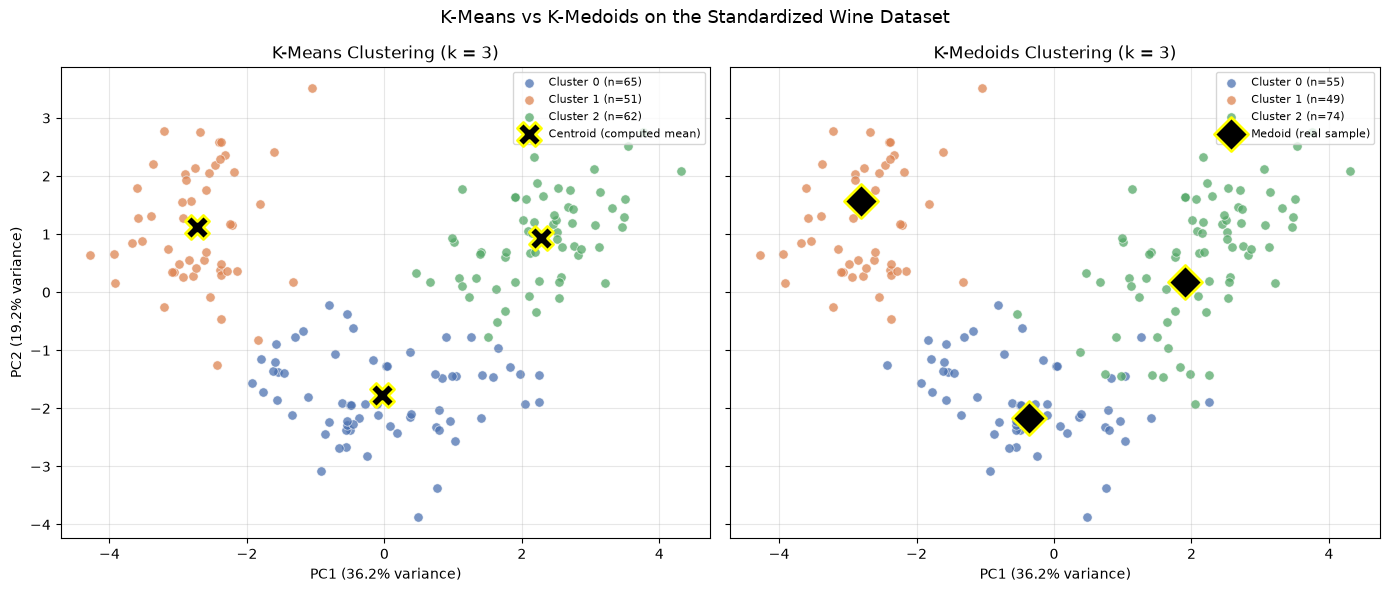

In [17]:
# Project the K-Means centroids into PCA space for plotting. The medoids are real
# samples, so their projected coordinates are already in X_pca.
centroids_pca = pca.transform(kmeans.cluster_centers_)
medoids_pca = X_pca[medoid_indices]

palette = ['#4C72B0', '#DD8452', '#55A868']
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, labels, centers, title, marker, center_label in [
        (axes[0], kmeans_labels, centroids_pca, 'K-Means', 'X', 'Centroid (computed mean)'),
        (axes[1], kmedoids_labels, medoids_pca, 'K-Medoids', 'D', 'Medoid (real sample)')]:
    for cluster_id in range(3):
        mask = labels == cluster_id
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=palette[cluster_id],
                   s=45, alpha=0.75, edgecolors='white', linewidths=0.5,
                   label=f'Cluster {cluster_id} (n={mask.sum()})')
    # Oversized black marker so the center is unmistakable against the points.
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker=marker, s=300,
               edgecolors='yellow', linewidths=2, label=center_label, zorder=5)
    ax.set_title(f'{title} Clustering (k = 3)')
    ax.set_xlabel(f'PC1 ({explained[0]:.1%} variance)')
    ax.legend(loc='upper right', fontsize=8); ax.grid(alpha=0.3)

axes[0].set_ylabel(f'PC2 ({explained[1]:.1%} variance)')
plt.suptitle('K-Means vs K-Medoids on the Standardized Wine Dataset', fontsize=13)
plt.tight_layout(); plt.show()

The two partitions agree on the broad layout and disagree at the boundaries. The K-Means centroids sit near the visual middle of each group because they are averages. The K-Medoids markers sit slightly off center, since each one has to be an actual wine and no real sample happens to occupy the exact middle of a cluster. The K-Medoids boundary between the left and middle groups has also drifted, which is where its extra misassignments come from.

### 4.2 Metric Comparison

           Silhouette Score  Adjusted Rand Index
K-Means              0.2849               0.8975
K-Medoids            0.2676               0.7411


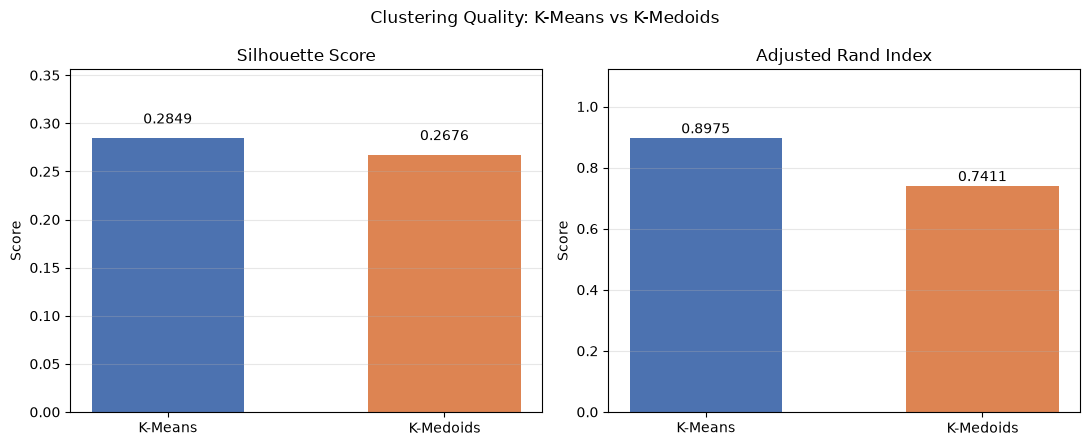

In [18]:
comparison = pd.DataFrame({
    'Silhouette Score': [kmeans_silhouette, kmedoids_silhouette],
    'Adjusted Rand Index': [kmeans_ari, kmedoids_ari]},
    index=['K-Means', 'K-Medoids']).round(4)
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric in zip(axes, ['Silhouette Score', 'Adjusted Rand Index']):
    bars = ax.bar(comparison.index, comparison[metric], color=['#4C72B0', '#DD8452'], width=0.55)
    for bar, value in zip(bars, comparison[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f'{value:.4f}', ha='center')
    ax.set_title(metric); ax.set_ylabel('Score')
    ax.set_ylim(0, max(comparison[metric]) * 1.25); ax.grid(axis='y', alpha=0.3)
plt.suptitle('Clustering Quality: K-Means vs K-Medoids')
plt.tight_layout(); plt.show()

K-Means wins on both. The silhouette gap is small, 0.2849 against 0.2676, so the two carve out clusters of similar tightness. The ARI gap is much wider, 0.8975 against 0.7411, meaning K-Means recovers the true cultivars considerably better even though its clusters are barely more compact.

### 4.3 Silhouette Profile per Cluster
The single silhouette number averages over all 178 samples and hides which clusters are the weak ones. Plotting per-sample values shows where each algorithm struggles.

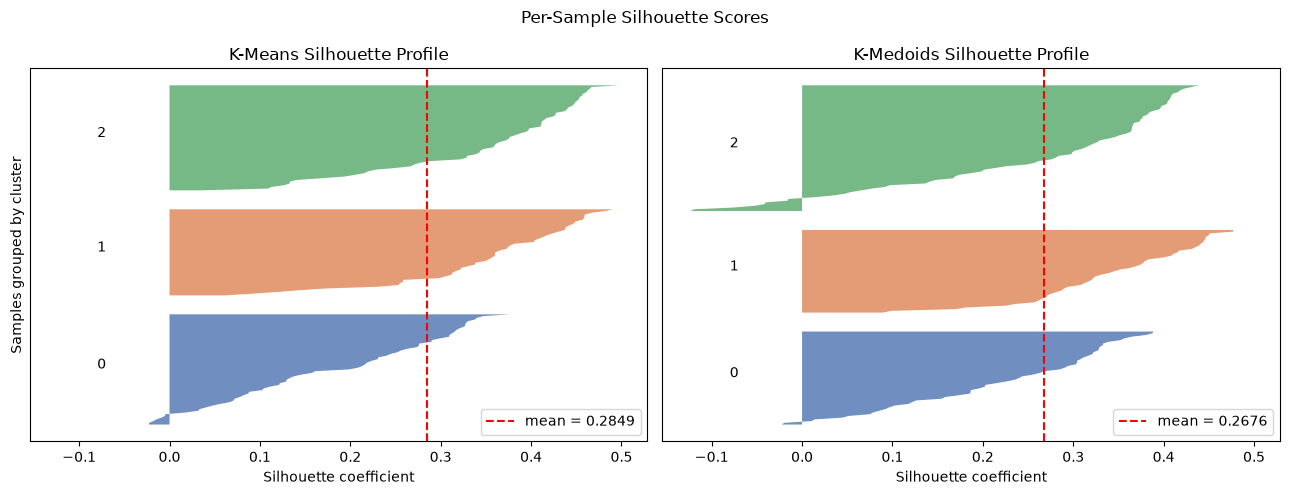

In [19]:
# silhouette_samples gives one score per point, so we can see per-cluster quality
# instead of one averaged number.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

for ax, labels, score, title in [
        (axes[0], kmeans_labels, kmeans_silhouette, 'K-Means'),
        (axes[1], kmedoids_labels, kmedoids_silhouette, 'K-Medoids')]:
    sample_scores = silhouette_samples(X, labels)
    y_lower = 10
    for cluster_id in range(3):
        values = np.sort(sample_scores[labels == cluster_id])
        y_upper = y_lower + len(values)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values,
                         facecolor=palette[cluster_id], alpha=0.8)
        ax.text(-0.08, y_lower + len(values) / 2, str(cluster_id))
        y_lower = y_upper + 10
    ax.axvline(score, color='red', linestyle='--', label=f'mean = {score:.4f}')
    ax.set_title(f'{title} Silhouette Profile')
    ax.set_xlabel('Silhouette coefficient'); ax.set_yticks([]); ax.legend(loc='lower right')

axes[0].set_ylabel('Samples grouped by cluster')
plt.suptitle('Per-Sample Silhouette Scores')
plt.tight_layout(); plt.show()

Both profiles show a few samples with negative coefficients, which are points sitting closer to a neighboring cluster than their own. K-Medoids has more of them, and they are concentrated in its largest cluster, the one that swallowed 74 samples. That is the same boundary drift visible in the scatter plot, now quantified.

### 4.4 Where the Two Algorithms Disagree

In [20]:
# Line up the two labelings against the true cultivars so the disagreement can be
# counted rather than eyeballed. Cluster numbering differs between the two runs,
# so map each cluster to the cultivar that dominates it first.
def align(labels, truth):
    """Relabel clusters to the cultivar that holds the majority of each cluster."""
    mapping = {}
    for cluster_id in np.unique(labels):
        mapping[cluster_id] = np.bincount(truth[labels == cluster_id]).argmax()
    return np.array([mapping[l] for l in labels])

kmeans_aligned = align(kmeans_labels, y_true)
kmedoids_aligned = align(kmedoids_labels, y_true)

km_wrong = kmeans_aligned != y_true
kd_wrong = kmedoids_aligned != y_true

print(f'Samples K-Means placed in the wrong cultivar group  : {km_wrong.sum()} of {len(y_true)}')
print(f'Samples K-Medoids placed in the wrong cultivar group: {kd_wrong.sum()} of {len(y_true)}')
print(f'Samples the two algorithms disagree on              : {(kmeans_aligned != kmedoids_aligned).sum()}')

Samples K-Means placed in the wrong cultivar group  : 6 of 178
Samples K-Medoids placed in the wrong cultivar group: 16 of 178
Samples the two algorithms disagree on              : 14


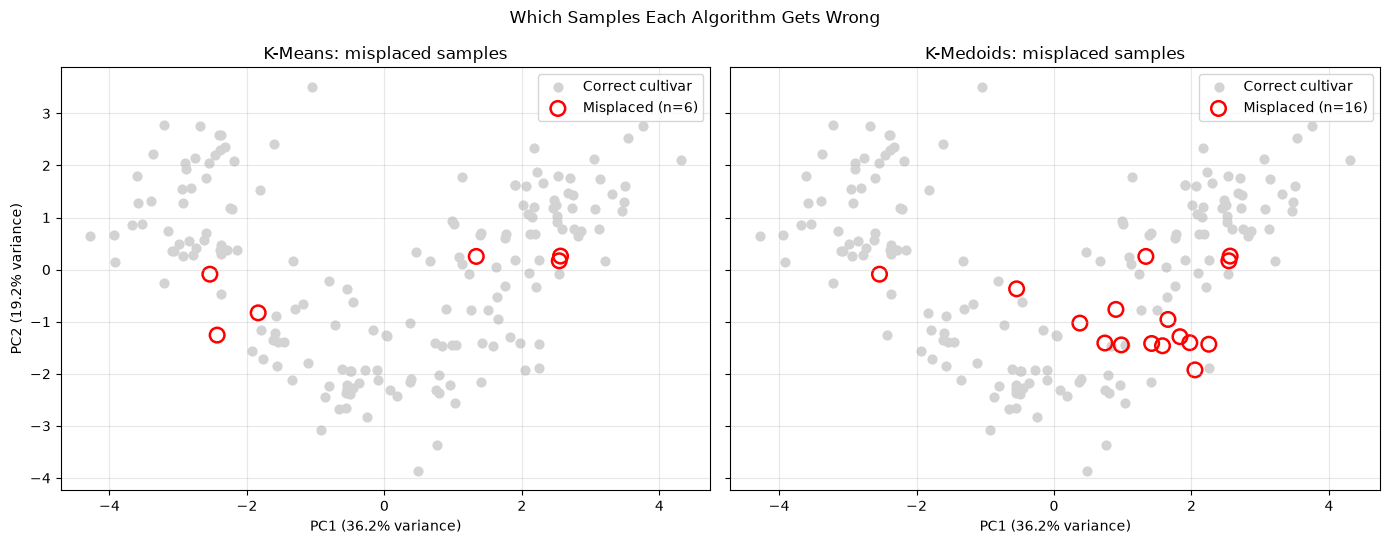

In [21]:
# Plot the mistakes directly: hollow red rings mark every misplaced sample.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, wrong, title, count in [
        (axes[0], km_wrong, 'K-Means', km_wrong.sum()),
        (axes[1], kd_wrong, 'K-Medoids', kd_wrong.sum())]:
    ax.scatter(X_pca[~wrong, 0], X_pca[~wrong, 1], c='lightgray', s=40,
               label='Correct cultivar')
    ax.scatter(X_pca[wrong, 0], X_pca[wrong, 1], facecolors='none', edgecolors='red',
               s=110, linewidths=1.8, label=f'Misplaced (n={count})')
    ax.set_title(f'{title}: misplaced samples')
    ax.set_xlabel(f'PC1 ({explained[0]:.1%} variance)')
    ax.legend(loc='upper right'); ax.grid(alpha=0.3)
axes[0].set_ylabel(f'PC2 ({explained[1]:.1%} variance)')
plt.suptitle('Which Samples Each Algorithm Gets Wrong')
plt.tight_layout(); plt.show()

K-Means misplaces 6 of 178 samples, K-Medoids misplaces 16, and the two disagree on 14. The red rings cluster along the seam between groups in both plots, which is the expected place for errors. K-Medoids adds a second band of mistakes further inside the left group, which is the cost of forcing its center onto a real sample that sits off center.

### 4.5 Analysis

**Which algorithm produced better-defined clusters?** K-Means, on both metrics. Silhouette 0.2849 against 0.2676 says its clusters are slightly tighter relative to their neighbors. ARI 0.8975 against 0.7411 is the bigger gap, and it says K-Means lines up with the actual cultivars far more closely: 6 misplaced samples against 16. The silhouette scores being so close while the ARI scores are far apart is worth noting on its own. It means the two algorithms found partitions of comparable geometric quality, but only one of them found the partition that matches the real chemistry.

**Differences in cluster shape and positioning.** K-Means centers land in the visual middle of each group because a centroid is an average and does not need to be a real wine. The K-Medoids markers are visibly off center, since the algorithm has to pick an actual sample and none of the 178 wines happens to sit at the exact middle of its group. That constraint moves the decision boundary too. K-Medoids pulled its largest cluster out to 74 samples, well past any true class size, absorbing points that K-Means assigned elsewhere, and the per-sample silhouette plot shows the extra negative scores piling up in exactly that cluster. Both algorithms make their mistakes in the same place, along the seam where `class_1` overlaps its neighbors in the PCA projection, which is a property of the data rather than of either method.

**When each is preferable.** K-Means is the better pick on this dataset and generally when the features are standardized, the clusters are roughly round and similar in size, and there are no extreme outliers. It is also faster: it only needs distances between points and `k` centers, while PAM builds the full 178 by 178 distance matrix and rescans every cluster member on each iteration.

K-Medoids earns its place when outliers are a real concern, because a medoid cannot be dragged toward an extreme value the way a mean can. It also works when only a distance or dissimilarity matrix exists and no meaningful average can be computed, which covers categorical data, Gower distance, edit distance on strings, and similar cases where K-Means simply does not apply. The other practical advantage is that each center is a real record, so a medoid can be inspected as a representative example. Here that showed up as three actual wines, one from each cultivar, which is more directly useful for interpretation than three averaged coordinate vectors.

For the Wine dataset specifically, standardization already removed the scale problem that would have hurt K-Means, and the leftover outliers in `magnesium` and `proanthocyanins` were not severe enough to cost it anything. K-Medoids gave up accuracy without getting much robustness benefit in return, which is why its ARI came out lower.